## 1.Machine Learning Classification and Ensemble Learning

## Project Overview

This project focuses on understanding and comparing different machine learning classification algorithms using synthetically generated datasets.

The main objective is to analyze how different classification algorithms behave on datasets with different geometric structures, evaluate their decision boundaries, and compare individual learning algorithms with ensemble learning methods.

### Project Objectives

- Generate synthetic datasets for classification tasks.
- Explore binary and multiclass classification concepts.
- Apply different machine learning algorithms.
- Visualize and compare decision boundaries.
- Investigate the differences between individual classifiers and ensemble learning.
- Evaluate model performance using training and test accuracy.

In [51]:
# Numerical Computing
import numpy as np
import pandas as pd

# Data Visualization
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Data Preprocessing and Splitting
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

# Dataset Generation
from sklearn.datasets import (
    make_moons,
    make_circles,
    make_classification
)

# Classification Algorithms
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Ensemble Learning
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


## 2. Dataset Generation and Exploratory Data Analysis (EDA)

In this section, three synthetic datasets are generated using Scikit-learn to investigate the behavior of different classification algorithms under various data distributions.

A fixed random state of 42 is used to ensure reproducibility.

### 2.1. Synthetic Classification Dataset

The `make_classification()` function is used to generate a binary classification dataset with 200 samples and 2 features.

The dataset contains two classes, with 20% label noise introduced through the `flip_y` parameter. The generated data is visualized using a scatter plot to examine the distribution of the classes.

### 2.2. Moon Dataset

The `make_moons()` function generates a binary classification dataset consisting of two interleaving half-moon shapes.

A noise level of 0.1 is applied to introduce variation into the data points. This dataset helps investigate how classification algorithms handle non-linearly separable data.

### 2.3. Circle Dataset

The `make_circles()` function generates a binary classification dataset consisting of two concentric circles.

The `factor` parameter is set to 0.5, defining the relative size of the inner circle, while a noise level of 0.1 is applied.

This dataset provides an opportunity to examine how different algorithms identify non-linear decision boundaries.

### Exploratory Data Analysis

Scatter plots are used to visualize the generated datasets and understand their geometric structures, class distributions, and noise characteristics.

These visualizations provide an initial understanding of the classification problems before applying machine learning algorithms.

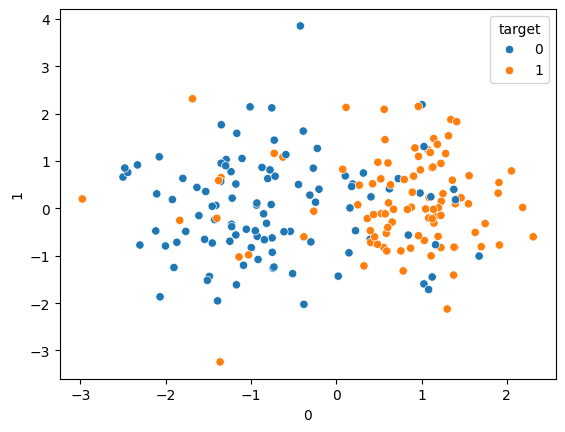

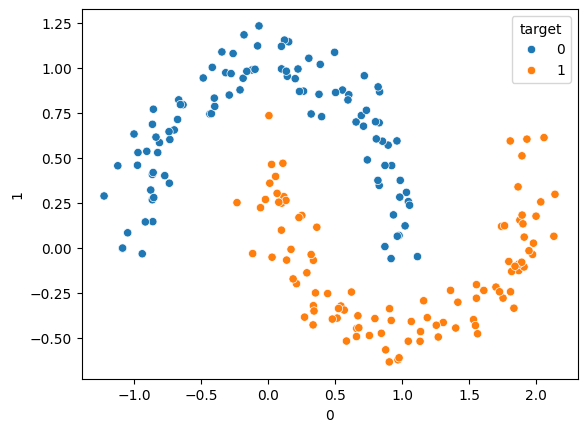

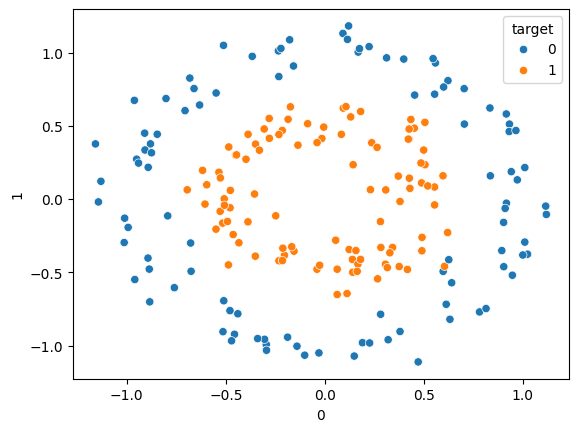

In [54]:
# %% Data Sets

random_state = 42

n_samples = 200
n_features = 2
n_classes = 2

noise_moon=0.1
noise_class = 0.2
noise_circle=0.1

X, y = make_classification(n_samples = n_samples,
                           n_features = n_features,
                           n_classes = n_classes,
                           n_repeated = 0,
                           n_redundant = 0,
                           n_informative = n_features-1,
                           random_state = random_state,
                           n_clusters_per_class = 1,
                           flip_y = noise_class)

data = pd.DataFrame(X)
data["target"] = y
plt.figure()
sns.scatterplot(x = data.iloc[:,0], y = data.iloc[:,1], hue = "target", data = data )


data_classification = (X,y)

moon = make_moons(n_samples = n_samples, noise = noise_moon, random_state = random_state)

data = pd.DataFrame(moon[0])
data["target"] = moon[1]
plt.figure()
sns.scatterplot(x = data.iloc[:,0], y = data.iloc[:,1], hue = "target", data = data )

circle = make_circles(n_samples = n_samples, factor=0.5, noise = noise_circle, random_state = random_state)
data = pd.DataFrame(circle[0])
data["target"] = circle[1]
plt.figure()
sns.scatterplot(x = data.iloc[:,0], y = data.iloc[:,1], hue = "target", data = data )

datasets=[moon,circle]



## 3. Model Initialization

In this section, four machine learning classification algorithms are initialized to compare their performance on the generated datasets.

The selected algorithms represent different learning approaches:

- **Support Vector Machine (SVM):** A classification algorithm that finds an optimal decision boundary by maximizing the margin between classes.
- **K-Nearest Neighbors (KNN):** A distance-based algorithm that classifies samples according to the majority class among their nearest neighbors. The number of neighbors is set to 5.
- **Decision Tree (DT):** A tree-based algorithm that makes classification decisions through a sequence of feature-based splits. The maximum tree depth is limited to 2.
- **Random Forest (RF):** An ensemble learning algorithm that combines multiple decision trees to improve classification performance. The number of estimators is set to 100, and the maximum tree depth is limited to 2.

All models are initialized with their selected hyperparameters and stored in a common list to facilitate systematic training and performance comparison.

The same classification algorithms will be evaluated on the generated datasets to investigate their learning behavior and decision boundaries.

In [55]:
n_estimators = 100


svc=SVC()
knn=KNeighborsClassifier(n_neighbors=15)
dt=DecisionTreeClassifier(random_state=random_state, max_depth=2)

rf=RandomForestClassifier(n_estimators=n_estimators, random_state=random_state, max_depth=2)


names = ["SVC", "KNN", "Decision Tree", "Random Forest"]
classifiers = [svc, knn, dt, rf]

## 4. Model Training, Evaluation and Decision Boundary Visualization

In this section, the selected classification algorithms are trained and evaluated on the Moon and Circle datasets.

The following steps are performed:

1. **Feature Scaling:** RobustScaler is applied to scale the input features and reduce the influence of outliers.
2. **Train-Test Split:** Each dataset is divided into training (60%) and testing (40%) sets.
3. **Model Training:** SVM, KNN, Decision Tree, and Random Forest classifiers are trained using the training data.
4. **Performance Evaluation:** Training and test accuracy scores are calculated to evaluate model performance and generalization.
5. **Decision Boundary Visualization:** The decision regions learned by each classifier are visualized in a two-dimensional feature space.

Different colors represent different predicted classes. Training samples are displayed as circles, while test samples are represented by triangles.

The purpose of these visualizations is to understand how different algorithms separate the classes and how dataset geometry influences their classification behavior.

The test accuracy percentage is also displayed on each plot to facilitate visual comparison of model performance.

Dataset # 0
SVC: test set score: 0.9750
SVC: train set score: 0.9917

KNN: test set score: 0.9750
KNN: train set score: 0.9917

Decision Tree: test set score: 0.9125
Decision Tree: train set score: 0.9333

Random Forest: test set score: 0.8875
Random Forest: train set score: 0.9250

-----------------------------------
Dataset # 1
SVC: test set score: 0.9750
SVC: train set score: 1.0000

KNN: test set score: 0.9125
KNN: train set score: 0.9667

Decision Tree: test set score: 0.7125
Decision Tree: train set score: 0.8000

Random Forest: test set score: 0.9625
Random Forest: train set score: 1.0000

-----------------------------------


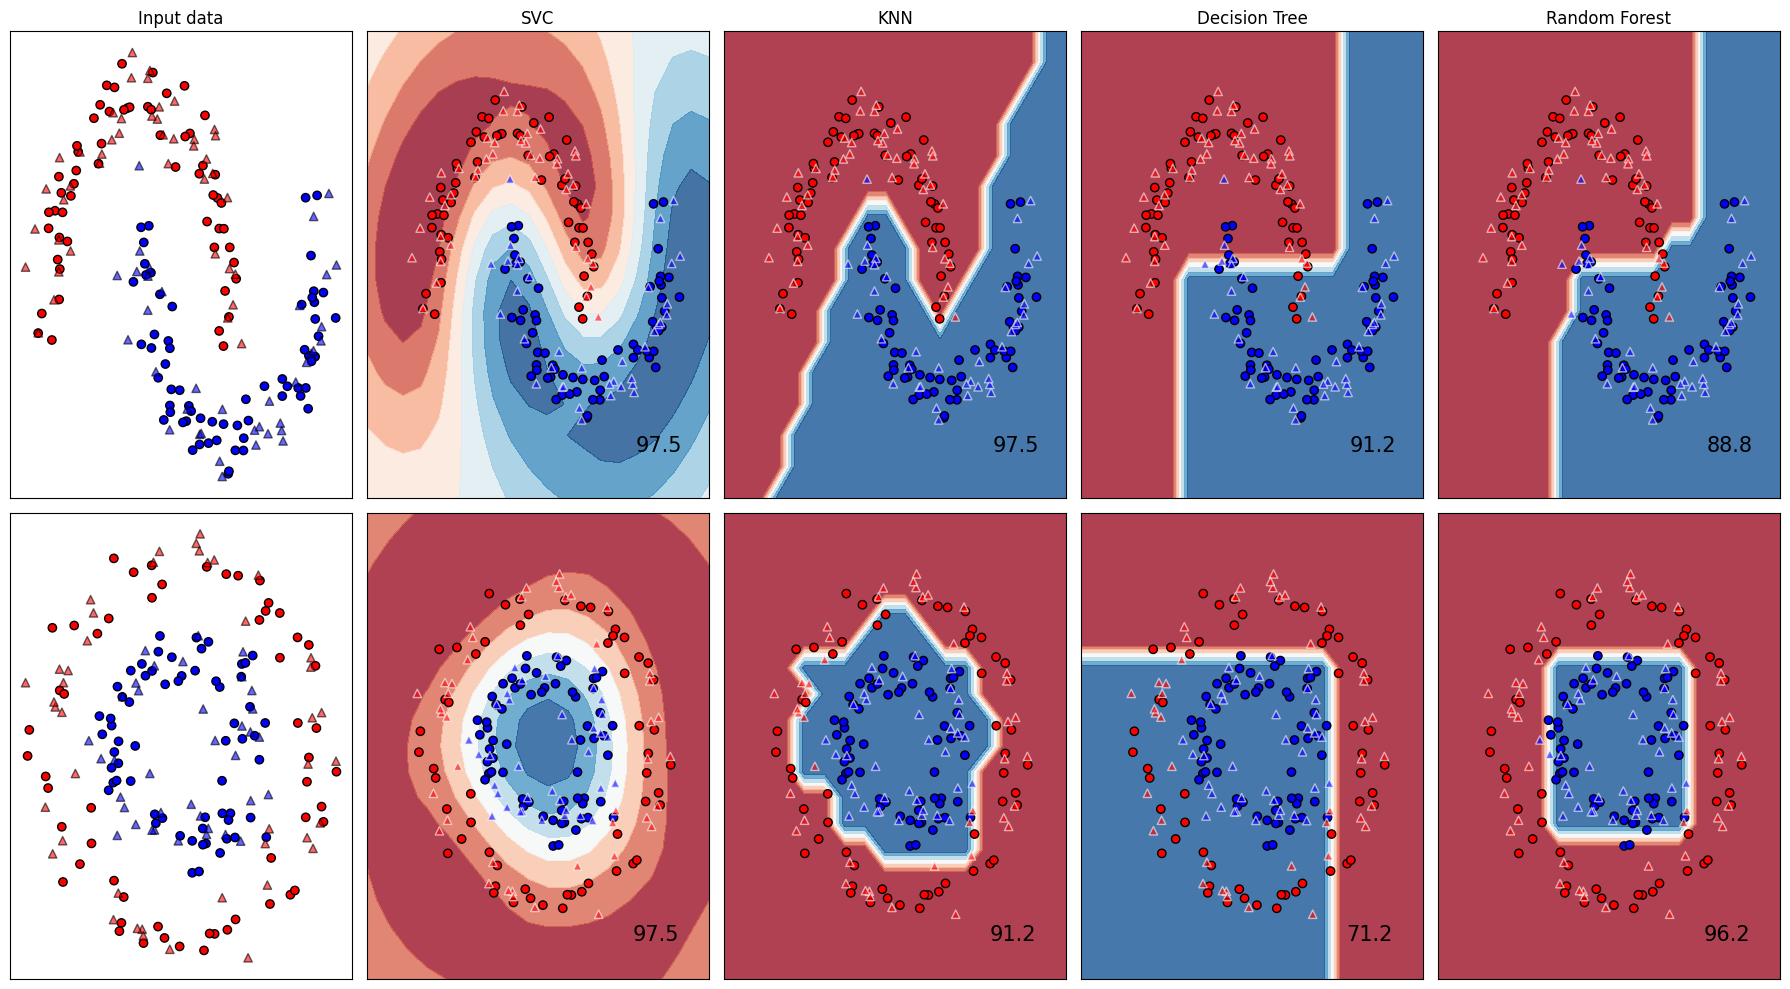

In [56]:

h = 0.2
random_state = 42

# Renk haritaları
cm = plt.cm.RdBu
cm_bright = ListedColormap(['#FF0000', '#0000FF'])

# 2 veri seti x (1 veri seti görseli + 3 model) = 8 grafik
fig, axes = plt.subplots(
    len(datasets),
    len(classifiers) + 1,
    figsize=(18, 10)
)

for ds_cnt, ds in enumerate(datasets):

    # Veri setini al
    X, y = ds

    # Ölçeklendirme
    X = RobustScaler().fit_transform(X)

    # Eğitim ve test ayrımı
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.4,
        random_state=random_state
    )

    # Karar sınırı için grid oluştur
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, h),
        np.arange(y_min, y_max, h)
    )

    # 1. Sütun: Orijinal veri seti
    ax = axes[ds_cnt, 0]

    if ds_cnt == 0:
        ax.set_title("Input data")

    ax.scatter(
        X_train[:, 0], X_train[:, 1],
        c=y_train,
        cmap=cm_bright,
        edgecolors='k'
    )

    ax.scatter(
        X_test[:, 0], X_test[:, 1],
        c=y_test,
        cmap=cm_bright,
        marker='^',
        alpha=0.6,
        edgecolors='k'
    )

    ax.set_xticks(())
    ax.set_yticks(())

    print("Dataset # {}".format(ds_cnt))

    # 2, 3 ve 4. Sütunlar: Sınıflandırma modelleri
    for model_cnt, (name, clf) in enumerate(zip(names, classifiers)):

        ax = axes[ds_cnt, model_cnt + 1]

        # Modeli eğit
        clf.fit(X_train, y_train)

        # Test ve eğitim doğrulukları
        score = clf.score(X_test, y_test)
        score_train = clf.score(X_train, y_train)

        print("{}: test set score: {:.4f}".format(name, score))
        print("{}: train set score: {:.4f}".format(name, score_train))

        # Karar sınırını hesapla
        if hasattr(clf, "decision_function"):
            Z = clf.decision_function(
                np.c_[xx.ravel(), yy.ravel()]
            )
        else:
            Z = clf.predict(
                np.c_[xx.ravel(), yy.ravel()]
            )

        Z = Z.reshape(xx.shape)

        # Karar bölgelerini çiz
        ax.contourf(
            xx, yy, Z,
            cmap=cm,
            alpha=0.8
        )

        # Eğitim verileri
        ax.scatter(
            X_train[:, 0], X_train[:, 1],
            c=y_train,
            cmap=cm_bright,
            edgecolors='k'
        )

        # Test verileri
        ax.scatter(
            X_test[:, 0], X_test[:, 1],
            c=y_test,
            cmap=cm_bright,
            marker='^',
            edgecolors='white',
            alpha=0.6
        )

        ax.set_xticks(())
        ax.set_yticks(())

        if ds_cnt == 0:
            ax.set_title(name)

        # Test doğruluğunu yüzde olarak göster
        ax.text(
            xx.max() - 0.3,
            yy.min() + 0.3,
            '{:.1f}'.format(score * 100),
            size=15,
            horizontalalignment='right'
        )

        print()

    print("-----------------------------------")

plt.tight_layout()
plt.show()

## 5. Classification Dataset – Model Training and Evaluation

In this section, the synthetic classification dataset generated using `make_classification` is used to evaluate the performance of different machine learning algorithms.

Unlike the Moon and Circle datasets, this dataset contains multiple numerical features, allowing the classifiers to learn from a higher-dimensional feature space.

The following steps are performed:

1. **Feature Scaling:** RobustScaler is applied to normalize the feature scales.
2. **Train-Test Split:** The dataset is divided into 60% training data and 40% testing data.
3. **Model Training:** SVM, KNN, Decision Tree, and Random Forest classifiers are trained on the same training dataset.
4. **Performance Evaluation:** Training and test accuracy scores are calculated for each classifier.

The results are used to compare the classification performance and generalization capabilities of the selected algorithms on the synthetic dataset.

In [57]:
def make_classify(dc, clf, name):
    x, y = dc
    x = RobustScaler().fit_transform(x)
    X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=.4, random_state=random_state)

    for name, clf in zip(names, classifiers):
        clf.fit(X_train, y_train)
        score = clf.score(X_test, y_test)
        print("{}: test set score: {} ".format(name, score))
        score_train = clf.score(X_train, y_train)
        print("{}: train set score: {} ".format(name, score_train))
        print()

print("Dataset # 2")
make_classify(data_classification, classifiers, names)

Dataset # 2
SVC: test set score: 0.8 
SVC: train set score: 0.8416666666666667 

KNN: test set score: 0.8 
KNN: train set score: 0.85 

Decision Tree: test set score: 0.8 
Decision Tree: train set score: 0.875 

Random Forest: test set score: 0.8 
Random Forest: train set score: 0.8666666666666667 

